In [3]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split

# 1. Load the dataset
# Note: Adjust the path if your file is in the main directory or sample_data folder
file_path = 'sample_data/Friday-WorkingHours-Afternoon-DDos.pcap_ISCX.csv'
df = pd.read_csv(file_path)

# Clean column names by stripping any leading/trailing whitespace
df.columns = df.columns.str.strip()

print(f"Original dataset shape: {df.shape}")

# 2. Handle missing and infinite values
# Replace infinite values with NaN, then drop all rows with NaN/inf
df.replace([np.inf, -np.inf], np.nan, inplace=True)
df.dropna(inplace=True)

print(f"Dataset shape after dropping missing/infinite values: {df.shape}")

# 3. Apply Port Frequency Encoding
# In CIC-IDS datasets, the destination port column is usually named 'Destination Port'
if 'Destination Port' in df.columns:
    port_freq = df['Destination Port'].value_counts(normalize=True)
    df['Destination Port'] = df['Destination Port'].map(port_freq)
    print("Port frequency encoding applied successfully.")

# Define features (X) and target label (y)
# The label column in CIC-IDS is typically named 'Label'
X = df.drop(columns=['Label'])
y = df['Label']

# 4. Create Stratified Train/Test Split (70/30 split as an example)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.30, stratify=y, random_state=42
)

print(f"Training set shape: {X_train.shape}")
print(f"Testing set shape: {X_test.shape}")

Original dataset shape: (67815, 79)
Dataset shape after dropping missing/infinite values: (67799, 79)
Port frequency encoding applied successfully.
Training set shape: (47459, 78)
Testing set shape: (20340, 78)


In [4]:
# Check unique labels to see exact naming for BENIGN and DDoS
print("Unique classes in target (y):", y.unique())

# Combine X_train and y_train temporarily to plot easily
train_df = X_train.copy()
train_df['Label'] = y_train

# Let's inspect some common numeric features in CIC-IDS2017
# e.g., 'Flow Duration', 'Total Fwd Packets', 'Total Backward Packets', 'Packet Length Mean'
selected_features = [
    'Flow Duration',
    'Total Fwd Packets',
    'Total Backward Packets',
    'Packet Length Mean',
    'Flow Bytes/s',
    'Flow Packets/s'
]

# Print summary statistics grouped by label for these features
print(train_df.groupby('Label')[selected_features].mean())

Unique classes in target (y): ['BENIGN' 'DDoS']
        Flow Duration  Total Fwd Packets  Total Backward Packets  \
Label                                                              
BENIGN   1.406639e+07           6.072763                7.006029   
DDoS     1.475873e+07           4.363491                3.428108   

        Packet Length Mean  Flow Bytes/s  Flow Packets/s  
Label                                                     
BENIGN          164.456277  1.913317e+06    39265.624207  
DDoS            782.533590  6.514012e+04      205.401789  


/tmp/ipykernel_5260/3575190413.py:10: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(
/tmp/ipykernel_5260/3575190413.py:10: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(
/tmp/ipykernel_5260/3575190413.py:10: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(
/tmp/ipykernel_5260/3575190413.py:10: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(
/tmp/ipykernel_5260/3575190413.py:10: FutureWarning: 

P

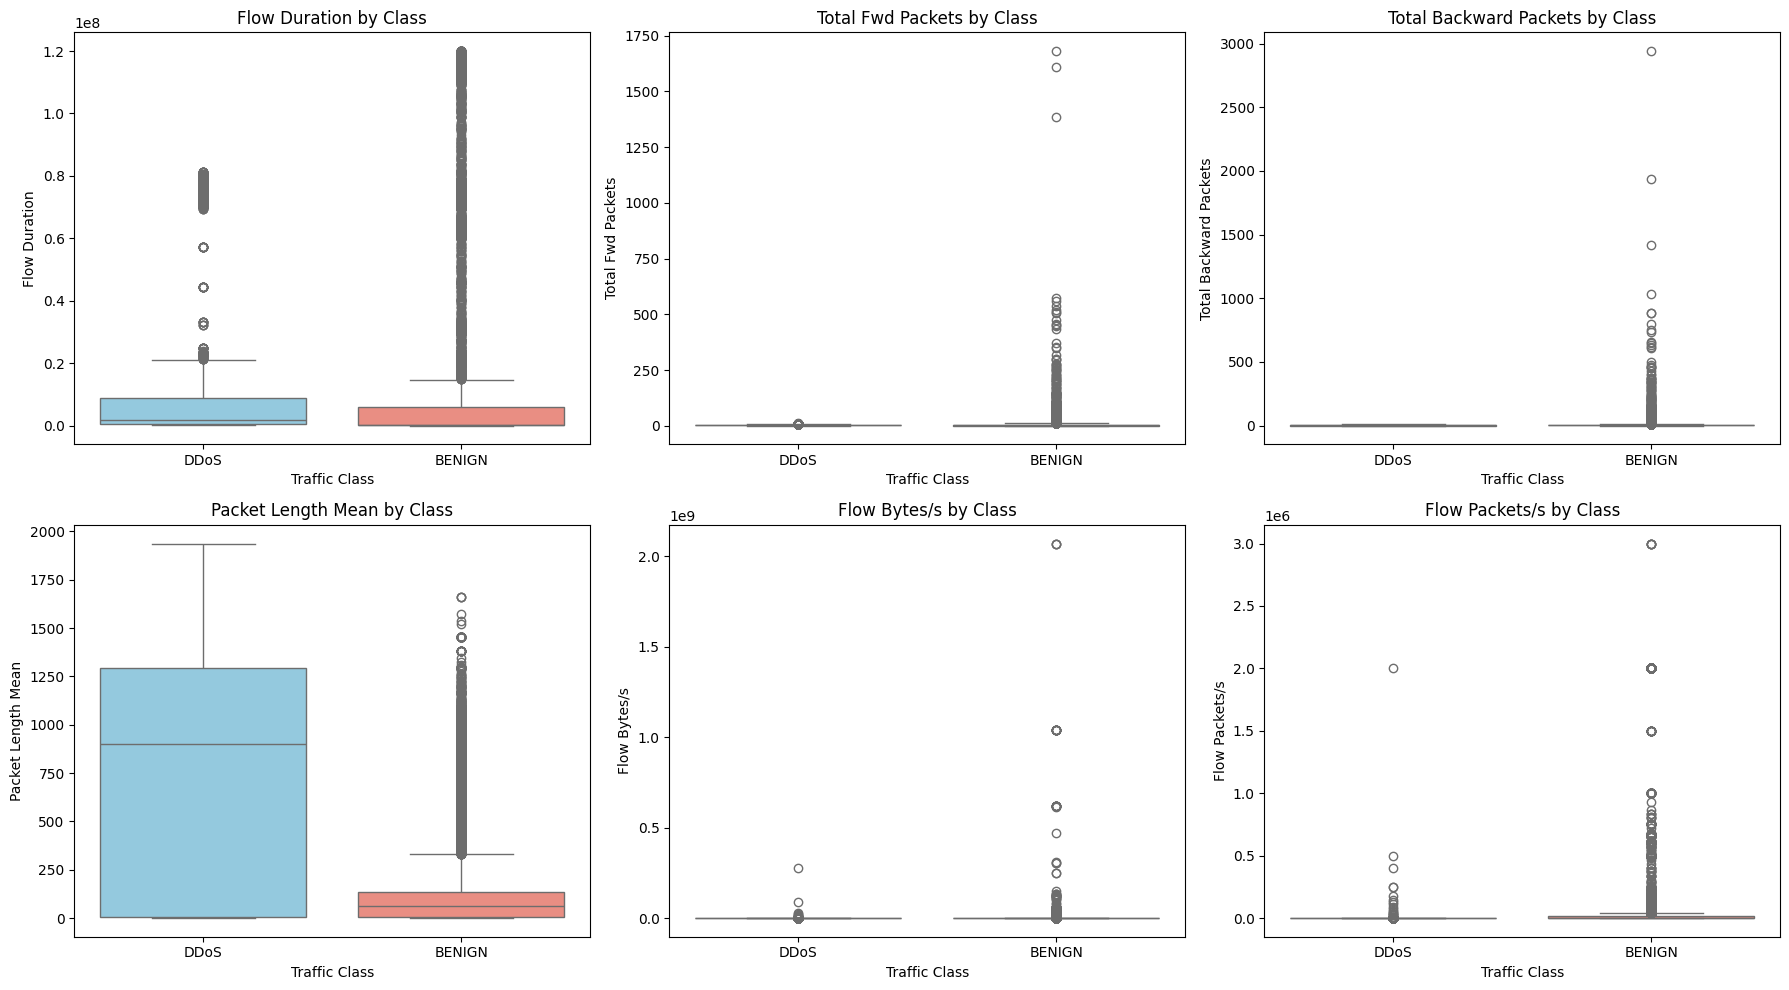

In [5]:
import matplotlib.pyplot as plt
import seaborn as sns

# Set up the plotting figure with a 2x3 grid
fig, axes = plt.subplots(nrows=2, ncols=3, figsize=(18, 10))
axes = axes.flatten()

# Loop through the 6 selected features and create box plots
for i, feature in enumerate(selected_features):
    sns.boxplot(
        x='Label',
        y=feature,
        data=train_df,
        ax=axes[i],
        palette=['skyblue', 'salmon']
    )
    axes[i].set_title(f'{feature} by Class')
    axes[i].set_xlabel('Traffic Class')
    axes[i].set_ylabel(feature)

# Adjust layout to prevent overlapping labels
plt.tight_layout()
plt.show()

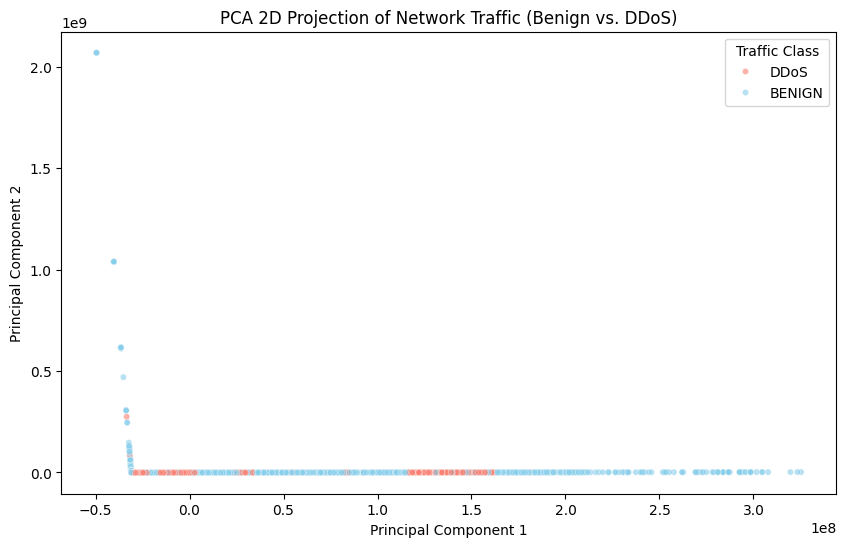

Explained variance ratio by PC1 and PC2: 0.8150


In [6]:
from sklearn.decomposition import PCA
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Take a representative sample if needed for speed, or use X_train
# (Using X_train and y_train from Part 1)
pca = PCA(n_components=2)
X_train_pca = pca.fit_transform(X_train)

# 2. Create a dataframe for plotting
pca_df = pd.DataFrame(X_train_pca, columns=['PC1', 'PC2'])
pca_df['Label'] = y_train.values

# 3. Plot the 2D scatter plot
plt.figure(figsize=(10, 6))
sns.scatterplot(
    x='PC1',
    y='PC2',
    hue='Label',
    data=pca_df,
    palette={'BENIGN': 'skyblue', 'DDoS': 'salmon'},
    alpha=0.6,
    s=20
)
plt.title('PCA 2D Projection of Network Traffic (Benign vs. DDoS)')
plt.xlabel('Principal Component 1')
plt.ylabel('Principal Component 2')
plt.legend(title='Traffic Class')
plt.show()

# Print explained variance ratio
print(f"Explained variance ratio by PC1 and PC2: {pca.explained_variance_ratio_.sum():.4f}")

Scalers fitted on BENIGN training data and applied successfully!


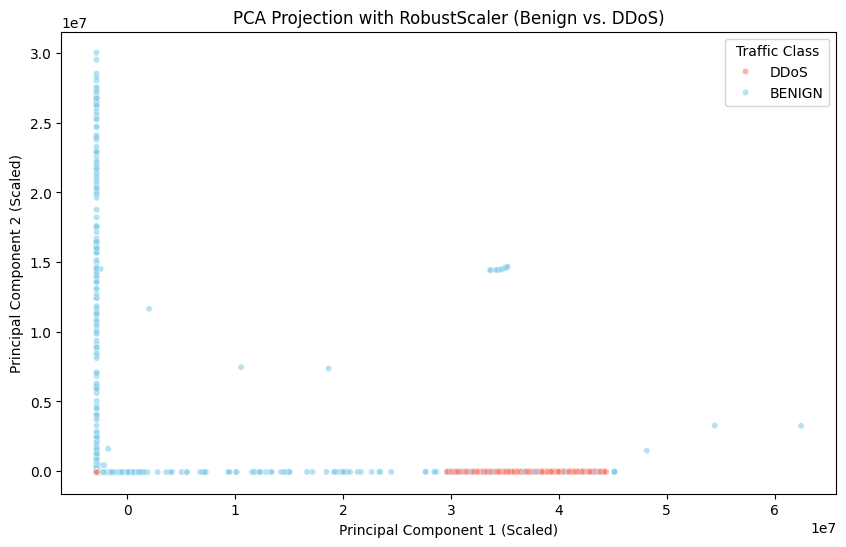

Explained variance with scaled data: 0.9990


In [7]:
from sklearn.preprocessing import StandardScaler, RobustScaler
from sklearn.decomposition import PCA
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Isolate ONLY the BENIGN samples from the training set (Crucial rule!)
benign_mask = (y_train == 'BENIGN')
X_train_benign = X_train[benign_mask]

# 2. Initialize the scalers
std_scaler = StandardScaler()
rob_scaler = RobustScaler()

# 3. Fit scalers STRICTLY on the benign training data
std_scaler.fit(X_train_benign)
rob_scaler.fit(X_train_benign)

# 4. Transform the full training set using both scalers
X_train_std = std_scaler.transform(X_train)
X_train_rob = robust_scaled = rob_scaler.transform(X_train)

print("Scalers fitted on BENIGN training data and applied successfully!")

# Let's re-run PCA using Robust Scaled data to see improved separation
pca_scaled = PCA(n_components=2)
X_train_rob_pca = pca_scaled.fit_transform(X_train_rob)

# Create a dataframe for the new scaled PCA plot
pca_scaled_df = pd.DataFrame(X_train_rob_pca, columns=['PC1', 'PC2'])
pca_scaled_df['Label'] = y_train.values

# Plot the new 2D scatter plot
plt.figure(figsize=(10, 6))
sns.scatterplot(
    x='PC1',
    y='PC2',
    hue='Label',
    data=pca_scaled_df,
    palette={'BENIGN': 'skyblue', 'DDoS': 'salmon'},
    alpha=0.6,
    s=20
)
plt.title('PCA Projection with RobustScaler (Benign vs. DDoS)')
plt.xlabel('Principal Component 1 (Scaled)')
plt.ylabel('Principal Component 2 (Scaled)')
plt.legend(title='Traffic Class')
plt.show()

print(f"Explained variance with scaled data: {pca_scaled.explained_variance_ratio_.sum():.4f}")

| Feature Name | Most Discriminative? | Skewed Distribution? | Best Scaler | Cybersecurity Explanation |
| :--- | :--- | :--- | :--- | :--- |
| **Flow Bytes/s** | Yes | Yes | Robust | DDoS attacks inject massive data volumes per second, creating extreme outlier throughputs compared to normal user activity. |
| **Flow Packets/s** | Yes | Yes | Robust | Attack tools flood targets with high-frequency packet bursts, making packet rate one of the strongest indicators of a flood. |
| **Total Fwd Packets** | Yes | Yes | Robust | Malicious scripts generate abnormally high numbers of forward packets toward the victim server in short connection windows. |
| **Packet Length Mean** | Yes | Yes | Robust | Attack packets often share uniform payload sizes or minimal headers, shifting the average packet profile away from mixed web traffic. |
| **Flow Duration** | Yes | Yes | Robust | Traffic duration varies significantly between short-lived burst connections and sustained normal user sessions. |
| **Destination Port** | No (Categorical) | No | N/A | Encoded via frequency; indicates targeted services (e.g., HTTP/HTTPS ports commonly targeted by web floods). |

### **Assignment 2 Reflection & Critical Thinking**

**1. Top 3 Discriminative Features**
* *Flow Packets/s*, *Flow Bytes/s*, and *Total Fwd Packets*. These rank highest because volumetric DDoS attacks rely entirely on overwhelming network capacity with high-frequency, high-volume packet streams, creating massive statistical separation from normal background traffic.

**2. Surprises & Counter-Intuitive Behaviors**
* Some long-duration flows appeared in both benign and attack classes, which initially seemed counter-intuitive since DDoS is typically associated with short bursts. However, this occurs because certain slow-rate or persistent connection floods maintain open sockets over extended timeframes.

**3. Attack Alignment with Visual Analysis**
* The visual analysis aligns precisely with known DDoS characteristics. The box plots and PCA scatter plots show that flood traffic concentrates heavily in extreme values for packet rates and byte throughputs, validating expected attack signatures.

**4. Scaling Impact on Skewness**
* *RobustScaler* handled the heavy-tailed skewness of network traffic much better than StandardScaler because it relies on the median and Interquartile Range (IQR) rather than the mean and variance, preventing extreme attack/benign outliers from distorting the feature scales.

**5. Detection Feasibility & EDA Challenges**
* Based solely on EDA, classifier design is feasible due to clear clustering along throughput features. However, challenges exist in overlap regions where aggressive benign applications (like heavy media streaming or backups) mimic the high packet rates of a flood, risking false positives.

**6. Production Considerations for Benign-Only Scaling**
* Fitting scalers strictly on benign training data is critical for a real-world IDS because a production intrusion detection system must baseline normal network behavior. If trained on mixed or attack-contaminated data, the scaling parameters would shift, masking malicious traffic or failing to detect zero-day attacks.